# Vantor Legion data tracking: site request and supplemental tasking vs CSDA STAC and ADAPT

Which Legion acquisitions at the requested sites are in CSDA STAC, do they meet the request, and are they on ADAPT? The request
is the `Legion_20260914` tab of the *Evaluation Site Requests* Google Sheet, plus the 3-day tasking windows at WLEF and Valencia
(`VantorLegion_Supp` tab of the On-Ramp 2 order tracking xlsx). Vantor's own catalog shows what has been collected but not
delivered.

## What this notebook gives you

Run it top to bottom. It ends with the same three results as the other tracking notebook
(`airbus_order_tracking.ipynb`), in section 8:

| Result | Section | Where to find it |
|---|---|---|
| **1. What is new** in CSDA STAC since the last run | 5 | `new`, and section 8 |
| **2. The HTML summary** of what is available | 6 | `SUMMARY_HTML`, linked from the timeline |
| **3. New data on ADAPT**: anything in CSDA STAC that is not on ADAPT yet is downloaded | 7 | `DOWNLOAD_DIR` |

| Section | What it does | Output |
|---|---|---|
| 1. What was requested | reads the site request and the tasking windows | `request`, `windows` |
| 2. Search CSDA STAC | every `maxar-legion` product at the requested sites | `res.gdf` |
| 3. What is on ADAPT | checks each product | `products` |
| 4. Compare with the request | checks the requirements, the tasking windows and Vantor's archive, shows what changed since `SINCE` | `acqs`, `request_summary`, `windows_summary`, `vantor_summary`, `since_summary` |
| 5. New since the last run | compares with the list saved by the last run | `products.new`, `new` |
| 6. HTML summary | per-site table of what is available | `SUMMARY_HTML`, `site_table` |
| 7. Download | fetches the products not on ADAPT; `DO_DOWNLOAD = False` only plans | `plan`, `check` |
| 8. Results | updates the page after the download, saves this run, prints the three results | `OUT_DIR/runs/` |

Sections 2, 3 and 5 to 8 work the same way in both notebooks (`lib/tracking_report.py`); only sections 1 and 4 are about Vantor Legion.

**What the words mean**

- **Available**: in CSDA STAC at the tracked sites. Section 2 always searches afresh, with no cache.
- **Acquisition**: one satellite pass (Vantor catalog ID). **Product**: one catalog item of it (for example pan or MS, TOA or SR).
- **New**: a product that was not in the list saved by the last run (`OUT_DIR/runs/products_YYYYMMDD.csv`). CSDA STAC does
  not record when an item was added, so this is how late deliveries of old acquisitions are found. The last run is the latest
  one before today, so running again the same day gives the same answer.
- **On ADAPT**: checked per product, so a new version of an acquisition already on ADAPT is still fetched. A product is on ADAPT
  if a folder `<dir>/<item id>/` in `ALREADY_HAVE_DIRS` holds all of its assets, or it is in `LOCAL_FOOTPRINTS`
  (from `footprint_CSDA_eval_all_data.ipynb`; rerun that after a download).

Runs in the **ILAB DEV kernel** (where `csda_client` is installed).

**About the request**

**Requirement checks** (from the request tab):
- **View angle**: `max_view_angle` against the acquisition's off-nadir angle (`view:off_nadir`).
- **Cloud**: STAC gives cloud cover for the whole scene only. A scene within the AOI limit passes. A scene above it is
  marked *check AOI* (`cloud_ok` empty) rather than failed, because the AOI itself may still be clear.
  (CSDA stores Legion cloud cover as a 0-1 fraction; `multistac` converts it to percent.)
- **Product**: MS requested -> the acquisition needs an MS product (pansharpened only does not count).
- **TOA / SR**: not in CSDA's STAC metadata, so not checked here.
- **'1 per sensor'** (e.g. Baotou): the count is the number of Legion sensors with at least one acquisition meeting the
  requirements, out of `LEGION_SENSORS`.

Vantor's archive (sections 4d and 4e) needs the `[Vantor_STAC_API]` key in `credentials.ini` (see `lib/stac_providers.yaml`).


**TOA and SR** are not in CSDA's STAC metadata either: both show as LV2A, and only the `.IMD` tells them apart. So the summary
knows a product's radiometry once it is on ADAPT.

Library: `lib/tracking_report.py` (the three results), `lib/order_tracking.py` (`read_legion_request`, `read_vantor_supp`),
`lib/multistac.py` (search).

In [1]:
import sys
sys.path.append('/home/pmontesa/code/csda_summaries/lib')

import importlib
from pathlib import Path
import pandas as pd
from IPython.display import Markdown
import multistac, multistac_plots, order_tracking, tracking_report
for m in (multistac, multistac_plots, order_tracking, tracking_report):
    importlib.reload(m)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.max_rows', 200)

## Parameters

In [2]:
VENDOR = 'Vantor Legion'
SITES = '/home/pmontesa/code/csda_summaries/sites/csda_sites_aoi_Vantor_Legion_20260922.geojson'
SITE_NAME_FIELD = 'Site Name'
SITE_ALIASES = {}   # sheet name -> name in the sites file
START, END = '2024-01-01', pd.Timestamp.today().strftime('%Y-%m-%d')   # before the first Legion launch (May 2024)
PROVIDERS = {'csda': ['maxar-legion']}
SINCE = '2026-09-01'                          # section 4e summary: images acquired on or after this date

# What was requested
# Site request: 'Evaluation Site Requests' Google Sheet, tab Legion_20260914 (gid from the tab's URL)
REQUEST_SHEET_ID = '16VopHRqlt5qbl4HgZdkVLUIHLVi9lZWPLJMY-QWsJ8g'
REQUEST_GID = 226856298
REQUEST_DATE = '2026-09-14'                   # acquisitions before this are archive, on or after are after the request
LEGION_SENSORS = ['LG01', 'LG02', 'LG03', 'LG04', 'LG05', 'LG06']
CLOUD_COVER_MAX = None                        # max scene cloud cover (%) for both searches; None = no limit
# Supplemental tasking windows: On-Ramp 2 order tracking workbook
TRACKING_XLSX = '/home/pmontesa/code/csda_summaries/sites/OnRamp2_OrderTracking_August2026.xlsx'
TRACKING_SHEET = 'VantorLegion_Supp'
VANTOR_PROVIDERS = {'vantor': [s.lower() for s in LEGION_SENSORS]}   # Vantor Discovery API: Legion collections lg01-lg06
MATCH_SECONDS = 120                           # Vantor collect = CSDA acquisition: same site and sensor, times this close

# ADAPT
LOCAL_FOOTPRINTS = '/explore/nobackup/projects/CSDA_eval/footprints/footprints_CSDA_eval_ACQUISITIONS_latest.csv'   # one row per local product
DOWNLOAD_DIR = Path('/explore/nobackup/projects/CSDA_eval/Data/Maxar/Legion/augmentation')
ALREADY_HAVE_DIRS = [Path('/explore/nobackup/projects/CSDA_eval/Data/Maxar/Legion'), DOWNLOAD_DIR]   # <dir>/<item id>/ = already downloaded
PRODUCTS_CSV = DOWNLOAD_DIR / 'legion_request_products.csv'   # site and acquisition of each downloaded product

# Results
OUT_DIR = '/explore/nobackup/people/pmontesa/multistac/legion_tracking'   # OUT_DIR/runs/ keeps each run's product list
SUMMARY_HTML = '/home/pmontesa/code/csda_summaries/html/augmentation/legion_augmentation_summary.html'

# Download (section 7)
DO_DOWNLOAD = True       # False: plan only
MEETS_ONLY = False       # True: only acquisitions meeting the site requirements (section 4a)
DOWNLOAD_ALL = True      # True: every asset (images + sidecars). False: metadata only
MAX_WORKERS = 8
CREDENTIALS_FILE = '/home/pmontesa/code/credentials.ini'


## 1. What was requested

### 1a. The Legion site request

Read live from the Google Sheet (shared as 'anyone with the link'), so edits to the tab show up on the next run.

In [3]:
request = order_tracking.read_legion_request(order_tracking.google_sheet_csv_url(REQUEST_SHEET_ID, REQUEST_GID),
                                             site_aliases=SITE_ALIASES)
print(f"{len(request)} requested sites")
request[['site_name', 'eval_category', 'max_view_angle', 'max_cloud_pct_aoi', 'max_cloud_pct_scene', 'pan', 'ms', 'toa',
         'sr', 'min_acqs', 'min_per_sensor', 'ideal_acqs', 'ideal_note'] + LEGION_SENSORS]

9 requested sites


,site_name,eval_category,max_view_angle,max_cloud_pct_aoi,max_cloud_pct_scene,pan,ms,toa,sr,min_acqs,min_per_sensor,ideal_acqs,ideal_note,LG01,LG02,LG03,LG04,LG05,LG06
0,Baotou,Radiometric & Geometric,15.0,0.0,NaN,False,True,True,False,1,True,<NA>,,?,?,?,?,?,?
1,Gobabeb,Radiometric,10.0,NaN,NaN,False,True,True,False,5,False,10,,?,?,?,?,?,?
2,La Crau,Radiometric & Geometric,10.0,NaN,NaN,False,True,True,False,<NA>,False,<NA>,,?,?,?,?,?,?
3,PICS Libya-4,Radiometric,NaN,0.0,NaN,False,True,True,False,5,False,10,*,?,?,?,?,?,?
4,Railroad Valley,Radiometric,10.0,NaN,NaN,False,True,True,False,5,False,10,,?,?,?,?,?,?
5,Sioux Falls,Geometric,10.0,NaN,NaN,False,True,True,False,5,False,10,,?,?,?,?,?,?
6,Valencia,Radiometric,10.0,NaN,NaN,False,True,False,True,3,False,15,,?,?,?,?,?,?
7,Golmud,Radiometric,10.0,NaN,NaN,False,True,True,False,5,False,10,,?,?,?,?,?,?
8,WLEF,Radiometric,10.0,NaN,NaN,False,True,False,True,3,False,15,,?,?,?,?,?,?


### 1b. The supplemental tasking windows

One row per tasking order. `window` numbers the orders of a site in sheet order (1 = first window). Each End is the next
window's Start, so a window is `[Start, End)`.

In [4]:
windows = order_tracking.read_vantor_supp(TRACKING_XLSX, TRACKING_SHEET, site_aliases=SITE_ALIASES)
SUPP_START = windows.window_start.min()
print(f"{len(windows)} tasking orders at {windows.site_name.nunique()} sites, "
      f"windows {SUPP_START:%Y-%m-%d} to {windows.window_end.max():%Y-%m-%d}")
print('Filled in the sheet so far:',
      {c: int(windows[c].notna().sum()) for c in ['catalog_id', 'order_date', 'date_received', 'toa_radiance', 'surface_refl']})
windows.groupby('site_name').agg(orders=('order_id', 'size'), first_window=('window_start', 'min'),
                                 last_window_end=('window_end', 'max'), min_scenes=('min_scenes', 'first'),
                                 ideal_scenes=('ideal_scenes', 'first'), eval_category=('eval_category', 'first'))

30 tasking orders at 2 sites, windows 2026-09-17 to 2026-11-01
Filled in the sheet so far: {'catalog_id': 0, 'order_date': 0, 'date_received': 0, 'toa_radiance': 0, 'surface_refl': 0}


,orders,first_window,last_window_end,min_scenes,ideal_scenes,eval_category
site_name,,,,,,
Valencia,15,2026-09-17 00:00:00+00:00,2026-11-01 00:00:00+00:00,5,15,radiometric
WLEF,15,2026-09-17 00:00:00+00:00,2026-11-01 00:00:00+00:00,5,15,radiometric


## 2. Search CSDA STAC

In [5]:
sites = multistac.load_sites(SITES, site_name_field=SITE_NAME_FIELD)
requested_sites = set(request.site_name) | set(windows.site_name)
missing = sorted(requested_sites - set(sites.site_name))
if missing:
    print('Sites not in the sites file (add to SITE_ALIASES):', missing)
sites = sites[sites.site_name.isin(requested_sites)]
print(len(sites), 'sites:', ', '.join(sites.site_name))

9 sites: Baotou, Gobabeb, La Crau, PICS Libya-4, Railroad Valley, Sioux Falls, Valencia, Golmud, WLEF


ERROR 1: PROJ: proj_create_from_database: Open of /panfs/ccds02/app/modules/jupyter/ilab/dev/pytorch-kernel-copy_20260408/share/proj failed


In [6]:
%%time
res = multistac.search(sites, START, END, PROVIDERS, cloud_cover_max=CLOUD_COVER_MAX)   # no cache_dir: always a fresh search, so new deliveries are found
print(res)
res.log[res.log.status == 'failed']

searches:   0%|          | 0/9 [00:00<?, ?it/s]

searches:  33%|███▎      | 3/9 [00:00<00:00, 12.54it/s]

searches:  56%|█████▌    | 5/9 [00:00<00:00,  9.26it/s]

searches:  89%|████████▉ | 8/9 [00:00<00:00, 14.07it/s]

searches:  89%|████████▉ | 8/9 [00:19<00:00, 14.07it/s]

searches: 100%|██████████| 9/9 [02:00<00:00, 23.51s/it]

searches: 100%|██████████| 9/9 [02:00<00:00, 13.38s/it]

SearchResult(201 rows, 201 unique items, 0 failed tasks)
CPU times: user 385 ms, sys: 77.5 ms, total: 463 ms
Wall time: 2min 1s


,provider,collection,site_name,interval,status,count,matched,server_filters,error,seconds


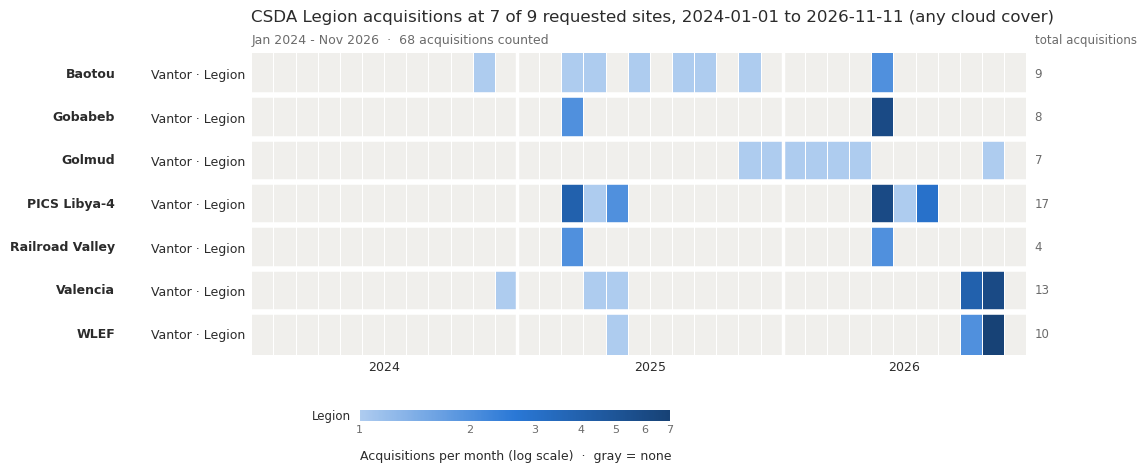

In [7]:
# Acquisitions: how often each site was imaged (products of one collect counted once)
HEATMAP_ROWS = ['site_name', 'affiliation', 'constellation']
cloud_txt = 'any cloud cover' if CLOUD_COVER_MAX is None else f'cloud cover <= {CLOUD_COVER_MAX}%'
multistac_plots.plot_month_heatmap(res.by_month(HEATMAP_ROWS, count='acquisitions'), color_by='constellation', max_rows=None,
                                   start=START[:7], end=END[:7],
                                   title=f'CSDA Legion acquisitions at {res.gdf.site_name.nunique()} of {len(sites)} requested sites, '
                                         f'{START} to {END} ({cloud_txt})');

## 3. What is on ADAPT

`products`: one row per CSDA product and site, with `on_adapt`. The check is explained at the top of this notebook.

In [8]:
products = tracking_report.products_table(res.gdf, bands=res.gdf['csda:band_count'])
local_copies = tracking_report.legion_local_copies(LOCAL_FOOTPRINTS)
products = tracking_report.legion_radiometry(products, LOCAL_FOOTPRINTS, ALREADY_HAVE_DIRS)
products = tracking_report.mark_on_adapt(products, res.items, ALREADY_HAVE_DIRS, local_copies)
print(f"{products[products.on_adapt].id.nunique()} of {products.id.nunique()} CSDA products on ADAPT")
tracking_report.acquisitions_table(products).groupby('site_name').agg(acquisitions=('acquisition_id', 'size'), on_adapt=('on_adapt', 'sum'))

201 of 201 CSDA products on ADAPT


,acquisitions,on_adapt
site_name,,
Baotou,9,9
Gobabeb,8,8
Golmud,7,7
PICS Libya-4,17,17
Railroad Valley,4,4
Valencia,13,13
WLEF,10,10


## 4. Compare with the request

### 4a. CSDA acquisitions vs the site requirements

One row per site and acquisition. `after_request` = acquired on or after `REQUEST_DATE`. `view_ok`, `ms_ok`, `cloud_ok` are the
checks (empty `cloud_ok` = scene above the AOI cloud limit: check the AOI); `meets` = all three.

In [9]:
key = lambda t: t.astype('datetime64[ns, UTC]')
g = res.gdf.copy()
g['datetime'] = pd.to_datetime(g.datetime, utc=True, format='mixed')
join = lambda s: ', '.join(sorted(s.dropna().astype(str).unique()))
acqs = (g.groupby(['site_name', 'acquisition_id'], as_index=False)
         .agg(csda_time=('datetime', 'min'), sensor=('sensor', 'first'), n_products=('id', 'nunique'),
              spectral_modes=('spectral_mode', join), processing_levels=('processing_level', join),
              off_nadir=('off_nadir', 'max'), cloud_pct=('cloud_cover', 'max')))
acqs = acqs[acqs.csda_time >= pd.Timestamp(START, tz='UTC')]   # STAC date ranges can reach back further
acqs['after_request'] = acqs.csda_time >= pd.Timestamp(REQUEST_DATE, tz='UTC')

req = request.set_index('site_name')

def check_requirements(df):
    # adds view_ok, ms_ok, cloud_ok, meets to a table with site_name, off_nadir, spectral_modes, cloud_pct
    limit = lambda col: df.site_name.map(req[col])
    df['view_ok'] = limit('max_view_angle').isna() | (df.off_nadir <= limit('max_view_angle'))
    df['ms_ok'] = ~limit('ms').fillna(False).astype(bool) | df.spectral_modes.str.contains(r'\bms\b')
    scene_ok = limit('max_cloud_pct_scene').isna() | (df.cloud_pct <= limit('max_cloud_pct_scene'))
    aoi_ok = limit('max_cloud_pct_aoi').isna() | (df.cloud_pct <= limit('max_cloud_pct_aoi'))
    df['cloud_ok'] = pd.array(scene_ok, dtype='boolean')
    df.loc[scene_ok & ~aoi_ok, 'cloud_ok'] = pd.NA                   # scene too cloudy for the AOI limit: check the AOI
    df.loc[~scene_ok, 'cloud_ok'] = False
    df['meets'] = df.view_ok & df.ms_ok & df.cloud_ok
    return df

acqs = check_requirements(acqs).sort_values(['site_name', 'csda_time']).reset_index(drop=True)
acqs = acqs.merge(tracking_report.acquisitions_table(products)[['site_name', 'acquisition_id', 'on_adapt']], how='left')

print(f"{len(acqs)} CSDA Legion acquisitions at {acqs.site_name.nunique()} sites, {START} to {END}: "
      f"{int(acqs.meets.fillna(False).sum())} meet the requirements, {int(acqs.meets.isna().sum())} to check (AOI cloud)")
print('Failing:', {c: int((~acqs[c].fillna(True)).sum()) for c in ['view_ok', 'ms_ok', 'cloud_ok']})
acqs

68 CSDA Legion acquisitions at 7 sites, 2024-01-01 to 2026-11-11: 28 meet the requirements, 1 to check (AOI cloud)
Failing: {'view_ok': 35, 'ms_ok': 4, 'cloud_ok': 0}


,site_name,acquisition_id,csda_time,sensor,n_products,spectral_modes,processing_levels,off_nadir,cloud_pct,after_request,view_ok,ms_ok,cloud_ok,meets,on_adapt
0,Baotou,LG02_20241120T033559,2024-11-20 03:35:59.871865+00:00,LG02,3,"ms, pan, pansharpened","LV2A, LV3D",7.4,0.0,False,True,True,True,True,True
1,Baotou,LG02_20250314T033953,2025-03-14 03:39:53.996935+00:00,LG02,1,pansharpened,LV3D,4.4,0.0,False,True,False,True,False,True
2,Baotou,LG04_20250424T003342,2025-04-24 00:33:42.622158+00:00,LG04,3,"ms, pan, pansharpened","LV2A, LV3D",14.0,0.0,False,True,True,True,True,True
3,Baotou,LG04_20250603T031825,2025-06-03 03:18:25.871847+00:00,LG04,1,pansharpened,LV3D,13.8,4.4,False,True,False,<NA>,False,True
4,Baotou,LG05_20250829T022328,2025-08-29 02:23:28.246798+00:00,LG05,1,pansharpened,LV3D,14.0,0.1,False,True,False,<NA>,False,True
5,Baotou,LG05_20250906T032136,2025-09-06 03:21:36.246792+00:00,LG05,1,pansharpened,LV3D,2.9,0.0,False,True,False,True,False,True
6,Baotou,LG06_20251125T071343,2025-11-25 07:13:43.746977+00:00,LG06,2,"ms, pan",LV2A,10.4,0.0,False,True,True,True,True,True
7,Baotou,LG03_20260503T000140,2026-05-03 00:01:40.621959+00:00,LG03,2,"ms, pan",LV2A,9.4,0.0,False,True,True,True,True,True
8,Baotou,LG01_20260512T035458,2026-05-12 03:54:58.746803+00:00,LG01,2,"ms, pan",LV2A,13.6,0.0,False,True,True,True,True,True
9,Gobabeb,LG01_20250302T091951,2025-03-02 09:19:51.246814+00:00,LG01,2,"ms, pan",LV2A,19.1,0.0,False,False,True,True,False,True


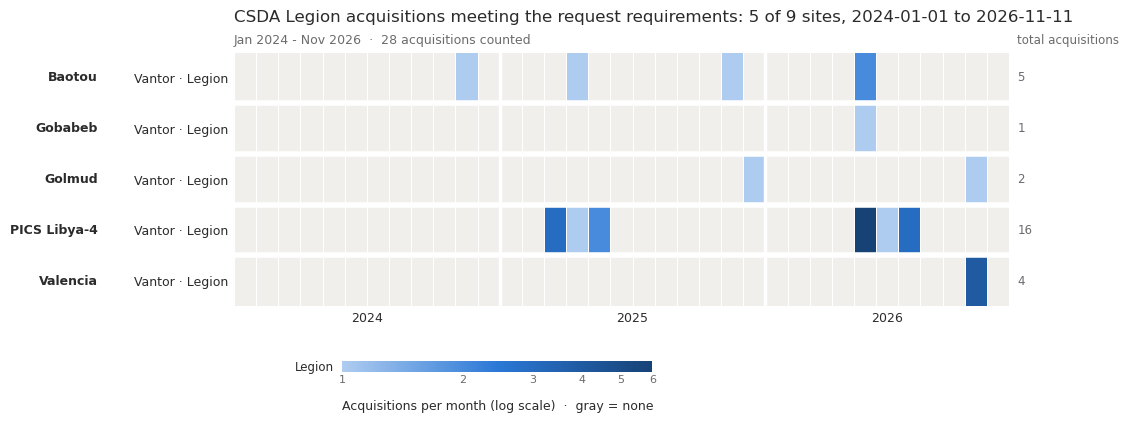

In [10]:
# Acquisitions that meet the site requirements (same layout and months as the plot above)
meets_gdf = g.merge(acqs.loc[acqs.meets.fillna(False), ['site_name', 'acquisition_id']])
multistac_plots.plot_month_heatmap(multistac.month_table(meets_gdf, HEATMAP_ROWS, count='acquisitions'), color_by='constellation',
                                   max_rows=None, start=START[:7], end=END[:7],
                                   title=f'CSDA Legion acquisitions meeting the request requirements: {acqs.loc[acqs.meets.fillna(False)].site_name.nunique()} '
                                         f'of {len(sites)} sites, {START} to {END}');

### 4b. Site request summary

Per site: acquisitions in CSDA, those meeting the requirements (all / archive / new), how many of those are on ADAPT,
and whether the count reaches the sheet's min / ideal. For '1 per sensor' sites the count is the number of sensors
(`LEGION_SENSORS`) with at least one acquisition meeting the requirements.

In [11]:
ok = acqs[acqs.meets.fillna(False)]
by_site = lambda df: df.groupby('site_name')
request_summary = request[['site_name', 'eval_category', 'max_view_angle', 'max_cloud_pct_aoi', 'min_acqs', 'min_per_sensor',
                           'ideal_acqs', 'ideal_per_sensor']].set_index('site_name')
request_summary['csda_acqs'] = by_site(acqs).size()
request_summary['meet_reqs'] = by_site(ok).size()
request_summary['meet_archive'] = by_site(ok[~ok.after_request]).size()
request_summary['meet_new'] = by_site(ok[ok.after_request]).size()
request_summary['to_check_aoi_cloud'] = by_site(acqs[acqs.meets.isna()]).size()
request_summary['meet_on_adapt'] = by_site(ok[ok.on_adapt]).size()
request_summary['sensors_meeting'] = by_site(ok).sensor.nunique()
request_summary['last_acq'] = by_site(acqs).csda_time.max().dt.strftime('%Y-%m-%d')
request_summary = request_summary.fillna({c: 0 for c in ['csda_acqs', 'meet_reqs', 'meet_archive', 'meet_new',
                                                          'to_check_aoi_cloud', 'meet_on_adapt', 'sensors_meeting']})
for kind in ('min', 'ideal'):
    count = request_summary.sensors_meeting.where(request_summary[f'{kind}_per_sensor'], request_summary.meet_reqs)
    target = request_summary[f'{kind}_acqs'].where(~request_summary[f'{kind}_per_sensor'], len(LEGION_SENSORS))
    request_summary[f'meets_{kind}'] = (count >= target).where(target.notna())   # empty = no number in the sheet
request_summary = request_summary.reset_index()
request_summary

,site_name,eval_category,max_view_angle,max_cloud_pct_aoi,min_acqs,min_per_sensor,ideal_acqs,ideal_per_sensor,csda_acqs,meet_reqs,meet_archive,meet_new,to_check_aoi_cloud,meet_on_adapt,sensors_meeting,last_acq,meets_min,meets_ideal
0,Baotou,Radiometric & Geometric,15.0,0.0,1,True,<NA>,False,9.0,5.0,5.0,0.0,0.0,5.0,5.0,2026-05-12,False,<NA>
1,Gobabeb,Radiometric,10.0,NaN,5,False,10,False,8.0,1.0,1.0,0.0,0.0,1.0,1.0,2026-05-29,False,False
2,La Crau,Radiometric & Geometric,10.0,NaN,<NA>,False,<NA>,False,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,<NA>,<NA>
3,PICS Libya-4,Radiometric,NaN,0.0,5,False,10,False,17.0,16.0,16.0,0.0,1.0,16.0,6.0,2026-07-19,True,True
4,Railroad Valley,Radiometric,10.0,NaN,5,False,10,False,4.0,0.0,0.0,0.0,0.0,0.0,0.0,2026-05-13,False,False
5,Sioux Falls,Geometric,10.0,NaN,5,False,10,False,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,False,False
6,Valencia,Radiometric,10.0,NaN,3,False,15,False,13.0,4.0,0.0,4.0,0.0,4.0,3.0,2026-10-29,True,False
7,Golmud,Radiometric,10.0,NaN,5,False,10,False,7.0,2.0,1.0,1.0,0.0,2.0,2.0,2026-10-27,False,False
8,WLEF,Radiometric,10.0,NaN,3,False,15,False,10.0,0.0,0.0,0.0,0.0,0.0,0.0,2026-10-24,False,False


### 4c. Supplemental tasking windows

CSDA acquisitions at the supplemental sites since the first window, matched to the window their acquisition time falls in
(none = outside every window).

In [12]:
cols = ['site_name', 'window', 'order_id', 'window_start', 'window_end']
supp = acqs[acqs.site_name.isin(windows.site_name) & (acqs.csda_time >= SUPP_START)]
supp = pd.merge_asof(supp.assign(t=key(supp.csda_time)).sort_values('t'),
                     windows[cols].assign(t=key(windows.window_start)).sort_values('t'),
                     on='t', by='site_name', direction='backward').drop(columns='t')
supp.loc[supp.csda_time >= supp.window_end, cols[1:]] = None
print(f"{len(supp)} CSDA Legion acquisitions at the supplemental sites since {SUPP_START:%Y-%m-%d}, "
      f"{supp.order_id.notna().sum()} inside a tasking window")
supp[['site_name', 'csda_time', 'sensor', 'window', 'order_id', 'off_nadir', 'cloud_pct', 'meets', 'on_adapt']]

19 CSDA Legion acquisitions at the supplemental sites since 2026-09-17, 19 inside a tasking window


,site_name,csda_time,sensor,window,order_id,off_nadir,cloud_pct,meets,on_adapt
0,Valencia,2026-09-19 13:49:51.246789+00:00,LG05,1.0,7071402682130601185-TASK,17.5,1.2,False,True
1,Valencia,2026-09-20 11:15:39.371809+00:00,LG02,2.0,7072131923213819090-TASK,16.7,1.0,False,True
2,WLEF,2026-09-23 14:27:04.246807+00:00,LG06,3.0,7072122180568733218-TASK,11.8,0.0,False,True
3,Valencia,2026-09-24 11:04:08.997415+00:00,LG01,3.0,7072138883106542798-TASK,18.3,0.0,False,True
4,WLEF,2026-09-26 13:39:37.496888+00:00,LG06,4.0,7072122818640781404-TASK,16.8,0.3,False,True
5,Valencia,2026-09-27 16:24:51.496989+00:00,LG03,4.0,7072132786220151333-TASK,13.8,11.4,False,True
6,WLEF,2026-10-01 17:08:52.996733+00:00,LG01,5.0,7072123327569366736-TASK,19.0,1.5,False,True
7,WLEF,2026-10-02 16:45:39.246910+00:00,LG05,6.0,7072123914259481841-TASK,17.5,0.0,False,True
8,WLEF,2026-10-05 20:39:03.246915+00:00,LG03,7.0,7072124363020828236-TASK,18.6,0.0,False,True
9,Valencia,2026-10-08 11:50:15.246913+00:00,LG03,8.0,7072140870481039638-TASK,15.9,6.8,False,True


In [13]:
today = pd.Timestamp.today(tz='UTC').normalize()
in_window = supp[supp.order_id.notna()]
windows_summary = windows.groupby('site_name').agg(orders=('order_id', 'size'), min_scenes=('min_scenes', 'first'),
                                                   ideal_scenes=('ideal_scenes', 'first'),
                                                   windows_closed=('window_end', lambda s: int((s <= today).sum())))
windows_summary['windows_with_data'] = in_window.groupby('site_name').order_id.nunique()
windows_summary['csda_acqs'] = in_window.groupby('site_name').acquisition_id.nunique()
windows_summary['meet_reqs'] = in_window[in_window.meets.fillna(False)].groupby('site_name').acquisition_id.nunique()
windows_summary['adapt_acqs'] = in_window[in_window.on_adapt].groupby('site_name').acquisition_id.nunique()
windows_summary = windows_summary.fillna(0).astype({c: int for c in ['windows_with_data', 'csda_acqs', 'meet_reqs', 'adapt_acqs']})
windows_summary['meets_min'] = windows_summary.csda_acqs >= windows_summary.min_scenes
windows_summary = windows_summary.reset_index()
windows_summary

,site_name,orders,min_scenes,ideal_scenes,windows_closed,windows_with_data,csda_acqs,meet_reqs,adapt_acqs,meets_min
0,Valencia,15,5,15,15,10,10,4,10,True
1,WLEF,15,5,15,15,9,9,0,9,True


### 4d. Vantor's archive vs CSDA since the request

Every Legion collect at the requested sites since `REQUEST_DATE` in Vantor's own catalog (Discovery API), checked against
the same requirements (Vantor strips are PAN + MS, so `ms_ok` always passes). A Vantor collect is in CSDA if a CSDA
acquisition of the same site and sensor is within `MATCH_SECONDS`. `not_in_csda` = collected by Vantor but not
delivered to CSDA yet: what to ask about.

In [14]:
%%time
vres = multistac.search(sites, REQUEST_DATE, END, VANTOR_PROVIDERS, cloud_cover_max=CLOUD_COVER_MAX)
print(vres)
vres.log[vres.log.status == 'failed']

searches:   0%|          | 0/54 [00:00<?, ?it/s]

searches:   2%|▏         | 1/54 [00:00<00:23,  2.30it/s]

searches:   4%|▎         | 2/54 [00:01<00:31,  1.63it/s]

searches:   6%|▌         | 3/54 [00:02<00:47,  1.07it/s]

searches:   7%|▋         | 4/54 [00:03<00:41,  1.20it/s]

searches:   9%|▉         | 5/54 [00:03<00:33,  1.45it/s]

... (34 outputs left out)

searches: 100%|██████████| 54/54 [00:11<00:00,  7.31it/s]

searches: 100%|██████████| 54/54 [00:11<00:00,  4.62it/s]

SearchResult(63 rows, 63 unique items, 0 failed tasks)
CPU times: user 383 ms, sys: 79.3 ms, total: 463 ms
Wall time: 14.3 s


,provider,collection,site_name,interval,status,count,matched,server_filters,error,seconds


In [15]:
v = vres.gdf.copy()
v['datetime'] = pd.to_datetime(v.datetime, utc=True, format='mixed')
vantor = (v.groupby(['site_name', 'acquisition_id'], as_index=False)
           .agg(vantor_time=('datetime', 'min'), sensor=('sensor', 'first'), spectral_modes=('spectral_mode', join),
                off_nadir=('off_nadir', 'max'), cloud_pct=('cloud_cover', 'max')))
vantor = check_requirements(vantor)

new_csda = acqs[acqs.after_request]
m = pd.merge_asof(vantor.assign(t=key(vantor.vantor_time)).sort_values('t'),
                  new_csda[['site_name', 'sensor', 'acquisition_id', 'csda_time']]
                      .rename(columns={'acquisition_id': 'csda_acquisition_id'}).assign(t=key(new_csda.csda_time)).sort_values('t'),
                  on='t', by=['site_name', 'sensor'], direction='nearest', tolerance=pd.Timedelta(seconds=MATCH_SECONDS))
vantor = vantor.merge(m[['site_name', 'acquisition_id', 'csda_acquisition_id']], how='left')
vantor['in_csda'] = vantor.csda_acquisition_id.notna()
vantor = vantor.sort_values(['site_name', 'vantor_time']).reset_index(drop=True)

vok = vantor[vantor.meets.fillna(False)]
vantor_summary = request[['site_name']].set_index('site_name')
vantor_summary['vantor_acqs'] = by_site(vantor).size()
vantor_summary['in_csda'] = by_site(vantor[vantor.in_csda]).size()
vantor_summary['not_in_csda'] = by_site(vantor[~vantor.in_csda]).size()
vantor_summary['vantor_meet_reqs'] = by_site(vok).size()
vantor_summary['meet_reqs_in_csda'] = by_site(vok[vok.in_csda]).size()
vantor_summary['meet_reqs_not_in_csda'] = by_site(vok[~vok.in_csda]).size()
vantor_summary['csda_new_acqs'] = by_site(new_csda).size()          # CSDA side, for a check: should equal in_csda
vantor_summary['last_vantor_acq'] = by_site(vantor).vantor_time.max().dt.strftime('%Y-%m-%d')
vantor_summary = vantor_summary.fillna({c: 0 for c in vantor_summary.columns if c != 'last_vantor_acq'})
vantor_summary = vantor_summary.astype({c: int for c in vantor_summary.columns if c != 'last_vantor_acq'}).reset_index()
print(f"Since {REQUEST_DATE}: {len(vantor)} Legion collects in Vantor's archive, {int(vantor.in_csda.sum())} in CSDA; "
      f"{len(vok)} meet the requirements, {int(vok.in_csda.sum())} of those in CSDA")
vantor_summary

Since 2026-09-14: 63 Legion collects in Vantor's archive, 20 in CSDA; 20 meet the requirements, 5 of those in CSDA


,site_name,vantor_acqs,in_csda,not_in_csda,vantor_meet_reqs,meet_reqs_in_csda,meet_reqs_not_in_csda,csda_new_acqs,last_vantor_acq
0,Baotou,0,0,0,0,0,0,0,NaN
1,Gobabeb,0,0,0,0,0,0,0,NaN
2,La Crau,5,0,5,5,0,5,0,2026-11-11
3,PICS Libya-4,9,0,9,5,0,5,0,2026-11-07
4,Railroad Valley,2,0,2,2,0,2,0,2026-10-27
5,Sioux Falls,0,0,0,0,0,0,0,NaN
6,Valencia,22,10,12,7,4,3,10,2026-10-29
7,Golmud,2,1,1,1,1,0,1,2026-10-27
8,WLEF,23,9,14,0,0,0,9,2026-10-28


### 4e. Summary since September

For images **acquired on or after `SINCE`** at the requested sites, for the timeline notes (section 5 is what changed since
the last run; this is what has arrived over a fixed period):

1. **New in CSDA STAC**: how many Legion images, at which sites, and how many meet the site requirements (section 4a)?
2. **Collected by Vantor but not in CSDA STAC yet**: Vantor's own catalog (Discovery API, fresh search) against CSDA. Only
   Vantor gives us this view of what has been collected.

In [16]:
vres_since = multistac.search(sites, SINCE, END, VANTOR_PROVIDERS, cloud_cover_max=CLOUD_COVER_MAX)
vg = vres_since.gdf.copy()
vg['datetime'] = pd.to_datetime(vg.datetime, utc=True, format='mixed')
collected = (vg.groupby(['site_name', 'acquisition_id'], as_index=False)
               .agg(vantor_time=('datetime', 'min'), sensor=('sensor', 'first'), spectral_modes=('spectral_mode', join),
                    off_nadir=('off_nadir', 'max'), cloud_pct=('cloud_cover', 'max')))
collected = check_requirements(collected)

since = pd.Timestamp(SINCE, tz='UTC')
csda_since = acqs[acqs.csda_time >= since]
m = pd.merge_asof(collected.assign(t=key(collected.vantor_time)).sort_values('t'),
                  csda_since[['site_name', 'sensor', 'acquisition_id', 'csda_time']]
                      .rename(columns={'acquisition_id': 'csda_acquisition_id'}).assign(t=key(csda_since.csda_time)).sort_values('t'),
                  on='t', by=['site_name', 'sensor'], direction='nearest', tolerance=pd.Timedelta(seconds=MATCH_SECONDS))
collected = collected.merge(m[['site_name', 'acquisition_id', 'csda_acquisition_id']], how='left')
collected['in_csda'] = collected.csda_acquisition_id.notna()
waiting = collected[~collected.in_csda]

meets = lambda df: df[df.meets.fillna(False)]
count = lambda df: by_site(df).size()
since_summary = pd.DataFrame({
    'new_in_csda': count(csda_since), 'new_in_csda_meeting_reqs': count(meets(csda_since)),
    'collected_by_vantor': count(collected), 'not_in_csda_yet': count(waiting),
    'not_in_csda_yet_meeting_reqs': count(meets(waiting))}).reindex(request.site_name).fillna(0).astype(int)
since_summary['latest_vantor_collect'] = by_site(collected).vantor_time.max().dt.strftime('%Y-%m-%d')
since_summary.loc['Total'] = since_summary.sum(numeric_only=True)
since_summary = since_summary.astype({c: int for c in since_summary.columns if c != 'latest_vantor_collect'})
unmatched = set(csda_since.acquisition_id) - set(collected.csda_acquisition_id.dropna())
print(f"Check: {len(unmatched)} CSDA images since {SINCE} not found in Vantor's catalog")
since_summary

searches:   0%|          | 0/54 [00:00<?, ?it/s]

searches:   2%|▏         | 1/54 [00:00<00:19,  2.73it/s]

searches:   6%|▌         | 3/54 [00:00<00:10,  4.85it/s]

searches:   7%|▋         | 4/54 [00:00<00:09,  5.39it/s]

searches:   9%|▉         | 5/54 [00:01<00:10,  4.83it/s]

searches:  11%|█         | 6/54 [00:01<00:13,  3.66it/s]

... (47 outputs left out)

searches: 100%|██████████| 54/54 [02:01<00:00, 32.36s/it]

searches: 100%|██████████| 54/54 [02:01<00:00,  2.25s/it]

Check: 0 CSDA images since 2026-09-01 not found in Vantor's catalog


,new_in_csda,new_in_csda_meeting_reqs,collected_by_vantor,not_in_csda_yet,not_in_csda_yet_meeting_reqs,latest_vantor_collect
site_name,,,,,,
Baotou,0,0,0,0,0,NaN
Gobabeb,0,0,0,0,0,NaN
La Crau,0,0,5,5,5,2026-11-11
PICS Libya-4,0,0,9,9,5,2026-11-07
Railroad Valley,0,0,2,2,2,2026-10-27
Sioux Falls,0,0,0,0,0,NaN
Valencia,10,4,23,13,3,2026-10-29
Golmud,1,1,2,1,0,2026-10-27
WLEF,9,0,23,14,0,2026-10-28


#### Conclusions and notes for `timeline.ipynb`

Plain-language text: the conclusions below, and the notes for the Vantor-Legion activities *Receive additional data
(radiometric)* and *Supplemental tasking windows* (paste into `timeline.ipynb` and re-run it).

In [17]:
today = pd.Timestamp.today().normalize()   # local date
d = lambda t: f"{pd.Timestamp(t):%-m/%-d/%y}"
per_site = lambda s: ', '.join(f"{k} {int(v)}" for k, v in s[s > 0].sort_values(ascending=False).items()) or 'none'
ss = since_summary.drop(index='Total')
n_new, n_col, n_wait = len(csda_since), len(collected), len(waiting)
quiet = ss[(ss.new_in_csda == 0) & (ss.collected_by_vantor == 0)].index
pct = lambda a, b: f"{round(100 * a / b)}%" if b else '-'

new_txt = (f"{n_new} Legion images acquired since {d(SINCE)} are in the CSDA STAC, at {(ss.new_in_csda > 0).sum()} of "
           f"{len(ss)} sites ({per_site(ss.new_in_csda)}); {len(meets(csda_since))} meet the site requirements.")
wait_txt = (f"Vantor has collected {n_col} Legion images at these sites since {d(SINCE)}; {n_wait} of them "
            f"({pct(n_wait, n_col)}) are not in the CSDA STAC yet ({per_site(ss.not_in_csda_yet)}), "
            f"and {len(meets(waiting))} of those meet the site requirements.")
quiet_txt = f"Nothing new since {d(SINCE)} at {', '.join(quiet)}." if len(quiet) else ''
ask_txt = (f"To ask Vantor: deliver the {n_wait} images not yet in CSDA, first the {len(meets(waiting))} that meet the "
           f"requirements ({per_site(meets(waiting).groupby('site_name').size())}).") if n_wait else ''
display(Markdown('\n'.join(f"- {t}" for t in [f"**As of {d(today)}**", new_txt, wait_txt, quiet_txt, ask_txt] if t)))

receive_note = ' '.join(t for t in [
    f"Status {d(today)} (images acquired since {d(SINCE)} at the {len(ss)} requested sites).",
    f"New in CSDA STAC: {n_new} images at {(ss.new_in_csda > 0).sum()} sites ({per_site(ss.new_in_csda)}); "
    f"{len(meets(csda_since))} meet the site requirements.",
    f"Collected by Vantor but not in CSDA STAC yet: {n_wait} of {n_col} ({pct(n_wait, n_col)}): {per_site(ss.not_in_csda_yet)}; "
    f"{len(meets(waiting))} of these meet the requirements.",
    f"Nothing new at {', '.join(quiet)}." if len(quiet) else ''] if t)

ws = windows_summary.merge(collected[collected.vantor_time >= SUPP_START].groupby('site_name').size().rename('vantor_since'),
                           left_on='site_name', right_index=True, how='left').fillna({'vantor_since': 0})
supp_note = (
    f"Extra Legion collections ordered at {len(ws)} sites, " + ' and '.join(ws.site_name)
    + f": {ws.orders.iloc[0]} three-day collection windows per site, {d(windows.window_start.min())}-"
    f"{d(windows.window_end.max())}. Goal: at least {ws.min_scenes.iloc[0]}, ideally {ws.ideal_scenes.iloc[0]}, "
    f"images per site. Collected by Vantor since {d(SUPP_START)}: "
    + ', '.join(f"{r.site_name} {int(r.vantor_since)}" for r in ws.itertuples())
    + ". In the CSDA STAC so far: "
    + '; '.join(f"{r.site_name} {r.csda_acqs} ({r.windows_with_data} of {r.orders} windows; {r.meet_reqs} within "
                f"the view-angle and cloud limits)" for r in ws.itertuples()) + '.')
print(receive_note, '\n')
print(supp_note)

- **As of 11/11/26**
- 20 Legion images acquired since 9/1/26 are in the CSDA STAC, at 3 of 9 sites (Valencia 10, WLEF 9, Golmud 1); 5 meet the site requirements.
- Vantor has collected 64 Legion images at these sites since 9/1/26; 44 of them (69%) are not in the CSDA STAC yet (WLEF 14, Valencia 13, PICS Libya-4 9, La Crau 5, Railroad Valley 2, Golmud 1), and 15 of those meet the site requirements.
- Nothing new since 9/1/26 at Baotou, Gobabeb, Sioux Falls.
- To ask Vantor: deliver the 44 images not yet in CSDA, first the 15 that meet the requirements (La Crau 5, PICS Libya-4 5, Valencia 3, Railroad Valley 2).

Status 11/11/26 (images acquired since 9/1/26 at the 9 requested sites). New in CSDA STAC: 20 images at 3 sites (Valencia 10, WLEF 9, Golmud 1); 5 meet the site requirements. Collected by Vantor but not in CSDA STAC yet: 44 of 64 (69%): WLEF 14, Valencia 13, PICS Libya-4 9, La Crau 5, Railroad Valley 2, Golmud 1; 15 of these meet the requirements. Nothing new at Baotou, Gobabeb, Sioux Falls. 

Extra Legion collections ordered at 2 sites, Valencia and WLEF: 15 three-day collection windows per site, 9/17/26-11/1/26. Goal: at least 5, ideally 15, images per site. Collected by Vantor since 9/17/26: Valencia 22, WLEF 23. In the CSDA STAC so far: Valencia 10 (10 of 15 windows; 4 within the view-angle and cloud limits); WLEF 9 (9 of 15 windows; 0 within the view-angle and cloud limits).


## 5. New since the last run

`products.new` = this product was not in the last run's list. `new_acquisition` = no product of this acquisition was.

In [18]:
products, last_run = tracking_report.compare_with_last_run(products, OUT_DIR)
meeting = acqs.loc[acqs.meets.fillna(False), 'acquisition_id']
products['wanted'] = products.acquisition_id.isin(meeting) if MEETS_ONLY else True   # every CSDA product at the requested sites
new = tracking_report.new_table(products)
new

,site_name,acquisition_id,sensor,acq_time,products,new_acquisition,radiometry,on_adapt


## 6. HTML summary

The page in `SUMMARY_HTML` is for the SMEs: what is new, what is available, what is on ADAPT, then the products and processing
levels at each site, what is still to come, and what the vendor terms mean. It is rewritten on every run, at the same address, so
the timeline link stays good. Section 8 writes it again after the download. Commit and push it to publish (GitHub Pages).

In [19]:
coming = since_summary[['collected_by_vantor', 'not_in_csda_yet', 'not_in_csda_yet_meeting_reqs', 'latest_vantor_collect']]
coming = coming.rename_axis('Site').reset_index().rename(columns={
    'collected_by_vantor': 'Collected by Vantor', 'not_in_csda_yet': 'Not in CSDA yet',
    'not_in_csda_yet_meeting_reqs': 'Of those, meeting the request', 'latest_vantor_collect': 'Latest collect'})
PAGE = dict(
    title='Vantor Legion data in CSDA STAC and on ADAPT',
    intro=f'Every Legion acquisition in CSDA STAC at the {len(sites)} requested sites, and what is on ADAPT '
          '(<code>CSDA_eval/Data/Maxar/Legion</code>). Affiliation <b>Maxar (Vantor)</b>.',
    notes=['<b>Acquisition</b> = one satellite pass (Vantor catalog ID). <b>Products</b> = pan and MS products; an acquisition '
           'delivered with both radiometric versions has four.',
           'CSDA STAC shows both radiometric versions as the same level, so radiometry is read from the <code>.IMD</code> and is '
           'known only for products on ADAPT.',
           'A Legion item ID ends in the product code: <code>200014660685_01_P001_M2AS</code> is multispectral (<code>M</code>), level 2A.'],
    labels=tracking_report.LEGION_RADIOMETRY_LABELS, sites=sites.site_name,
    coming=(f"Legion collects since {pd.Timestamp(SINCE):%-d %b %Y} in Vantor's own catalog that are not in CSDA STAC yet.", coming),
    other_page=('Airbus', 'airbus_augmentation_summary.html'))
tracking_report.write_summary_page(products, SUMMARY_HTML, last_run=last_run, **PAGE)
site_table = tracking_report.site_table(products)
site_table

,Site,Acqs,New,On ADAPT,Products,Products on ADAPT,TOA only,SR only,TOA + SR,Other,Sensors (acqs),Acquired
0,PICS Libya-4,17,0,17,50,50,0,10,7,0,"LG01 (3), LG02 (4), LG03 (3), LG04 (3), LG05 (...",2025-03-02 – 2026-07-19
1,Valencia,13,0,13,55,55,0,0,13,0,"LG01 (3), LG02 (3), LG03 (3), LG04 (2), LG05 (2)",2024-12-14 – 2026-10-29
2,WLEF,10,0,10,40,40,0,0,10,0,"LG01 (1), LG03 (3), LG04 (2), LG05 (2), LG06 (2)",2025-05-31 – 2026-10-24
3,Baotou,9,0,9,16,16,9,0,0,0,"LG01 (1), LG02 (2), LG03 (1), LG04 (2), LG05 (...",2024-11-20 – 2026-05-12
4,Gobabeb,8,0,8,16,16,8,0,0,0,"LG01 (2), LG02 (2), LG03 (1), LG04 (1), LG05 (...",2025-03-02 – 2026-05-29
5,Golmud,7,0,7,16,16,6,0,1,0,"LG01 (1), LG02 (1), LG04 (1), LG05 (2), LG06 (2)",2025-11-19 – 2026-10-27
6,Railroad Valley,4,0,4,8,8,4,0,0,0,"LG01 (1), LG02 (1), LG03 (1), LG06 (1)",2025-03-02 – 2026-05-13
7,Total,68,0,68,201,201,27,10,31,0,"LG01 (12), LG02 (13), LG03 (12), LG04 (11), LG...",2024-11-20 – 2026-10-29


## 7. Download

Every product in `plan` goes to `DOWNLOAD_DIR/<item id>/`: Earthdata login from `credentials.ini`, then `CsdaClient` and
`csdalib_download.download_all_assets` in a thread pool. Files already there are kept, so re-running resumes an interrupted
download. `PRODUCTS_CSV`, next to the data, says which site and acquisition each product belongs to.

In [20]:
plan = tracking_report.plan_download(products, res.items)
print(f"{len(plan)} products to download ({plan.GB.sum():.1f} GB), {plan.acquisition_id.nunique()} acquisitions")
plan.groupby(['site_name', 'sensor']).agg(acquisitions=('acquisition_id', 'nunique'), products=('id', 'size'), GB=('GB', 'sum')).round(2)

0 products to download (0.0 GB), 0 acquisitions


,,acquisitions,products,GB
site_name,sensor,,,


In [21]:
check = tracking_report.download(plan, res.items, products, DOWNLOAD_DIR, PRODUCTS_CSV, CREDENTIALS_FILE,
                                 do_download=DO_DOWNLOAD, download_all=DOWNLOAD_ALL, max_workers=MAX_WORKERS)
check[~check.complete] if check is not None else None

Nothing to download


## 8. Results

What is on ADAPT after the download, the page, this run's list for next time, and the three results.

In [22]:
products = tracking_report.legion_radiometry(products, LOCAL_FOOTPRINTS, ALREADY_HAVE_DIRS)
products = tracking_report.mark_on_adapt(products, res.items, ALREADY_HAVE_DIRS, local_copies)
tracking_report.write_summary_page(products, SUMMARY_HTML, last_run=last_run, plan=plan, check=check, download_dir=DOWNLOAD_DIR, **PAGE)
tracking_report.save_run(products, OUT_DIR, res.log)
display(Markdown(tracking_report.results(VENDOR, products, last_run, SUMMARY_HTML, plan, check, DO_DOWNLOAD)))

**Vantor Legion, as of 11/11/26**

1. Nothing new in CSDA STAC since the last run (11/10/26).
2. HTML summary updated: `/home/pmontesa/code/csda_summaries/html/augmentation/legion_augmentation_summary.html`. CSDA STAC has 68 acquisitions at 7 sites; 68 are on ADAPT (201 of 201 products).
3. Download: nothing to fetch, every wanted product is on ADAPT.